# Machine Failure Detection from Sensor Data
Stage 1: inspection, training-only exploration, and fixed splits. No models are trained.

We classify whether a machine has failed in the current record (1) or not (0). This is synthetic benchmark classification, not a forecast of a future breakdown.

Source: [UCI AI4I 2020](https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset), DOI: 10.24432/C5HS5C, CC BY 4.0. See data/README.md for attribution and download instructions.

In [1]:
from pathlib import Path
import hashlib
import json
import platform

import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split
from IPython.display import display

# Support Jupyter launched from either the repository or notebooks directory.
ROOT = Path.cwd()
if not (ROOT / "data").is_dir():
    ROOT = ROOT.parent
DATA_PATH = ROOT / "data" / "ai4i2020.csv"
RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)
RANDOM_STATE = 42
df = pd.read_csv(DATA_PATH)
df.index.name = "row_index"  # Original zero-based CSV data-row index; never reset.
data_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
print("Shape:", df.shape)
display(df.head())


Shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
row_index,,,,,,,,,,,,,,
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## Basic checks on the complete file
Schema, missingness, duplicate counts, and target totals describe the input. Modeling decisions and distribution plots below use only training rows. We keep all rows; duplicate counts alone do not justify deletion.

In [2]:
TARGET = "Machine failure"
FEATURES = [
    "Type", "Air temperature [K]", "Process temperature [K]",
    "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]",
]
IDENTIFIERS = ["UDI", "Product ID"]
FAILURE_MODES = ["TWF", "HDF", "PWF", "OSF", "RNF"]
assert set(df.columns) == set(FEATURES + IDENTIFIERS + [TARGET] + FAILURE_MODES)
assert df.shape == (10000, 14)
assert set(df[TARGET].unique()) == {0, 1}
schema = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "unique_values": df.nunique(),
})
display(schema)
duplicate_counts = {
    "full_rows": int(df.duplicated().sum()),
    "without_identifiers": int(df.drop(columns=IDENTIFIERS).duplicated().sum()),
    "predictors_only": int(df[FEATURES].duplicated().sum()),
}
print("Duplicate rows after the first occurrence:", duplicate_counts)
display(df[TARGET].value_counts().sort_index().rename("records").to_frame())
assert schema["missing"].sum() == 0
schema.to_csv(RESULTS / "schema.csv")


,dtype,missing,unique_values
UDI,int64,0,10000
Product ID,object,0,10000
Type,object,0,3
Air temperature [K],float64,0,93
Process temperature [K],float64,0,82
Rotational speed [rpm],int64,0,941
Torque [Nm],float64,0,577
Tool wear [min],int64,0,246
Machine failure,int64,0,2
TWF,int64,0,2


Duplicate rows after the first occurrence: {'full_rows': 0, 'without_identifiers': 0, 'predictors_only': 0}


,records
Machine failure,
0,9661
1,339


## Prevent target leakage
Only the six named predictors enter X. UDI and Product ID identify records/products rather than provide intended sensor predictors. TWF, HDF, PWF, OSF, and RNF describe failure outcomes; they reveal information about the answer and would give misleadingly strong performance. They are excluded even if they do not match the aggregate target perfectly.

Stratification keeps the rare failure class represented in every partition. Split once into 60% training and 40% temporary rows, then split those temporary rows equally. The training set guides exploration and fitting; validation will guide model/threshold choices; the test set is reserved for final evaluation.

In [3]:
X = df[FEATURES].copy()
y = df[TARGET].copy()
train_idx, temporary_idx = train_test_split(
    df.index, test_size=0.40, stratify=y, random_state=RANDOM_STATE
)
validation_idx, test_idx = train_test_split(
    temporary_idx, test_size=0.50, stratify=y.loc[temporary_idx],
    random_state=RANDOM_STATE
)
assignments = pd.Series(index=df.index, dtype="object", name="split")
assignments.loc[train_idx] = "train"
assignments.loc[validation_idx] = "validation"
assignments.loc[test_idx] = "test"
split_path = RESULTS / "split_assignments.csv"
metadata_path = RESULTS / "split_metadata.json"

# Never silently replace a saved experiment with different rows or source data.
metadata = {
    "dataset_sha256": data_hash, "random_state": RANDOM_STATE,
    "row_index": "zero-based original CSV data row",
    "method": "stratified 60/40, then stratified 50/50 of temporary rows",
    "python": platform.python_version(), "pandas": pd.__version__,
    "scikit_learn": sklearn.__version__, "matplotlib": matplotlib.__version__,
}
if split_path.exists():
    saved = pd.read_csv(split_path, index_col="row_index")["split"]
    pd.testing.assert_series_equal(saved, assignments)
    assert json.loads(metadata_path.read_text())["dataset_sha256"] == data_hash
    assignments = saved
else:
    assignments.to_csv(split_path)
    metadata_path.write_text(json.dumps(metadata, indent=2) + "\n")

groups = {name: set(assignments.index[assignments == name])
          for name in ["train", "validation", "test"]}
assert len(groups["train"]) == 6000
assert len(groups["validation"]) == len(groups["test"]) == 2000
assert groups["train"].isdisjoint(groups["validation"])
assert groups["train"].isdisjoint(groups["test"])
assert groups["validation"].isdisjoint(groups["test"])
assert set.union(*groups.values()) == set(df.index)
assert assignments.notna().all()
for indices in groups.values():
    assert set(y.loc[list(indices)].unique()) == {0, 1}

split_summary = pd.crosstab(assignments, y).reindex(["train", "validation", "test"])
split_summary.columns = ["no_failure", "failure"]
split_summary["total"] = split_summary.sum(axis=1)
split_summary["failure_rate"] = split_summary["failure"] / split_summary["total"]
display(split_summary)
split_summary.to_csv(RESULTS / "split_summary.csv")

# Reuse saved membership in this and later stages. No validation/test plots.
train_rows = assignments.index[assignments == "train"]
X_train = X.loc[train_rows]
y_train = y.loc[train_rows]
train = df.loc[train_rows, FEATURES + [TARGET]]
print("All split checks passed.")


,no_failure,failure,total,failure_rate
split,,,,
train,5797,203,6000,0.033833
validation,1932,68,2000,0.034000
test,1932,68,2000,0.034000


All split checks passed.


## Training-only exploration
Class imbalance means accuracy alone could hide missed failures. Later stages will compare a majority-class baseline, logistic regression, and random forest using precision, recall, F1, and confusion matrices. Validation data will be used to investigate thresholds; those claims are not completed in Stage 1.

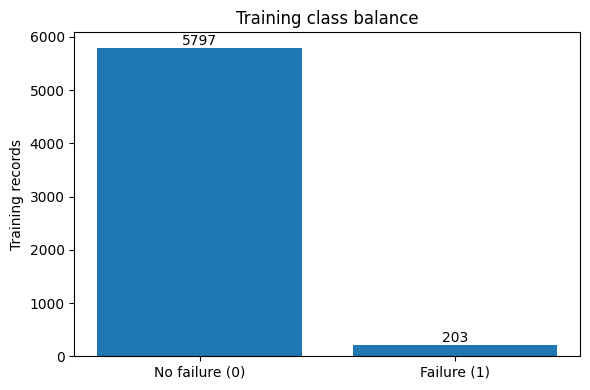

Training failures: 203 / 6000 (3.38%). Most records have no failure.


In [4]:
counts = y_train.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["No failure (0)", "Failure (1)"], counts.values)
ax.bar_label(bars)
ax.set(ylabel="Training records", title="Training class balance")
fig.tight_layout()
fig.savefig(RESULTS / "training_class_balance.png", dpi=150)
plt.show()
print(f"Training failures: {counts.loc[1]} / {len(y_train)} "
      f"({y_train.mean():.2%}). Most records have no failure.")


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
count,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000
mean,300.019783,310.012383,1538.869500,40.034067,107.492833
std,2.004329,1.479536,180.530086,10.035769,63.571628
min,295.300000,305.700000,1168.000000,3.800000,0.000000
25%,298.300000,308.800000,1422.000000,33.200000,52.000000
50%,300.100000,310.100000,1503.000000,40.100000,107.000000
75%,301.500000,311.100000,1614.000000,46.900000,162.000000
max,304.500000,313.800000,2886.000000,76.600000,253.000000


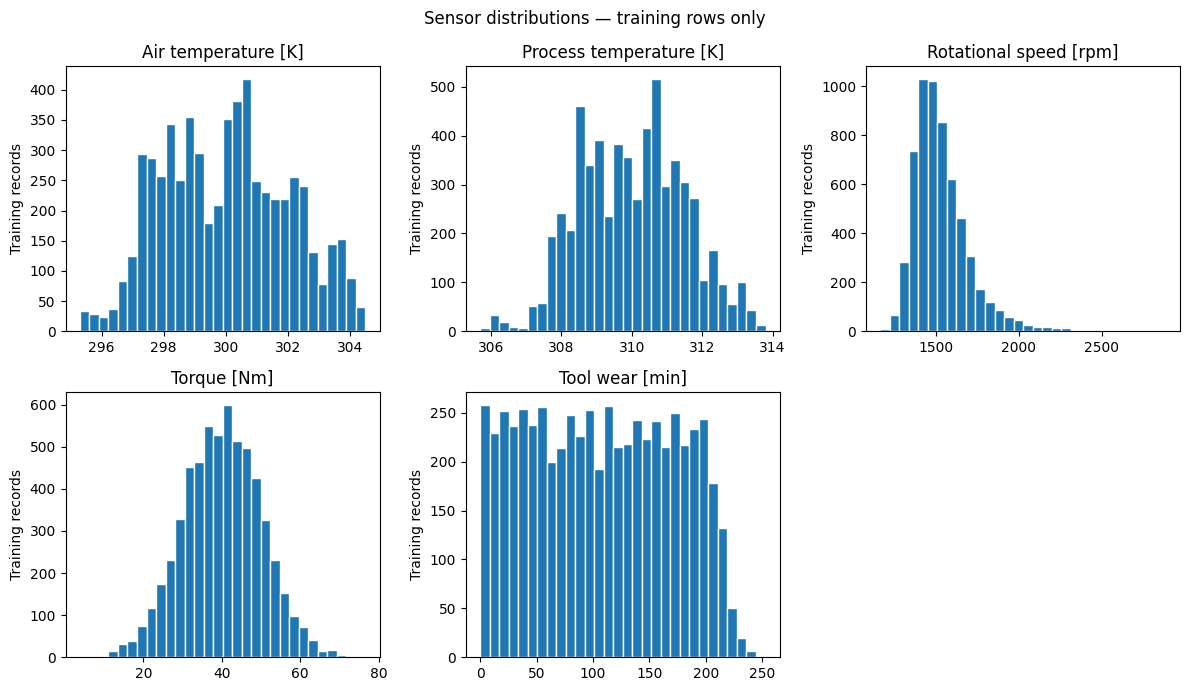

In [5]:
SENSORS = FEATURES[1:]
display(X_train[SENSORS].describe())
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for column, ax in zip(SENSORS, axes.flat):
    ax.hist(X_train[column], bins=30, edgecolor="white")
    ax.set(title=column, ylabel="Training records")
axes.flat[-1].set_visible(False)
fig.suptitle("Sensor distributions — training rows only")
fig.tight_layout()
fig.savefig(RESULTS / "training_sensor_distributions.png", dpi=150)
plt.show()


Rotational speed has a long right tail, torque is roughly bell-shaped, and tool wear spans much of its range with fewer observations near its upper end. Sensors use different units and scales, so later logistic regression preprocessing should fit scaling on training rows only. Extreme sensor values may be meaningful failure conditions; we do not remove them automatically.

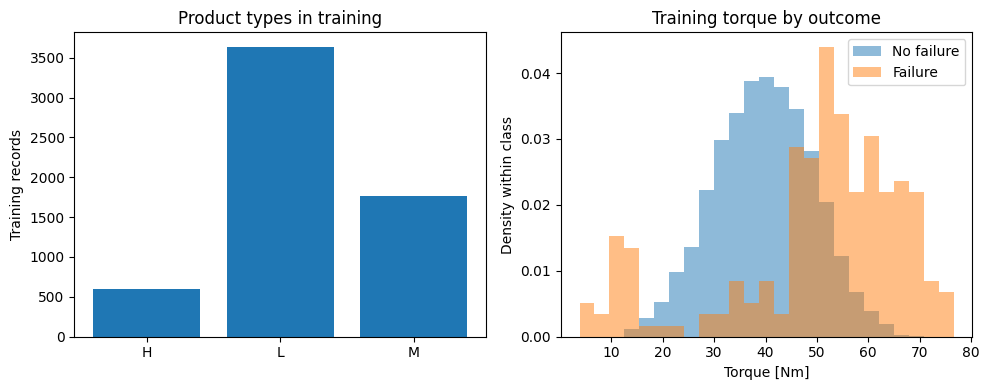

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
type_counts = X_train["Type"].value_counts().sort_index()
axes[0].bar(type_counts.index, type_counts.values)
axes[0].set(title="Product types in training", ylabel="Training records")
for label, name in [(0, "No failure"), (1, "Failure")]:
    axes[1].hist(train.loc[train[TARGET] == label, "Torque [Nm]"],
                 bins=25, range=(train[SENSORS[3]].min(), train[SENSORS[3]].max()), density=True, alpha=0.5, label=name)
axes[1].set(title="Training torque by outcome", xlabel="Torque [Nm]",
            ylabel="Density within class")
axes[1].legend()
fig.tight_layout()
fig.savefig(RESULTS / "training_type_and_torque.png", dpi=150)
plt.show()


Type L is most common in training and H is least common. Type is categorical: a future pipeline should encode it rather than assign an arbitrary numeric ranking. Failures appear more common at higher torque and at some low values, with overlap between classes. The torque overlay uses shared bins and density so the minority class remains visible; differences and overlap suggest hypotheses, not proof that torque causes failure. Read these plots alongside the printed counts and sensor summary.

## Limitations and next stage
The data are synthetic. A random split estimates performance within this benchmark, not on a real factory or on future breakdowns. UCI describes temperatures generated using random walks and tool wear accumulated across observations. Related ordered observations can land in different splits, making random-split estimates optimistic. There are no reliable timestamps or machine histories here to validate future-event forecasting.

No rows have been removed, no missing values imputed, and no models or thresholds fitted. In the next stage, load the saved row assignments and verify the dataset hash. Fit all preprocessing on training rows; choose models and thresholds using validation; evaluate the final frozen choice once on test rows.